# 第07章 信任的边界 · B2组复现与验证

B2（G20）· 第二轮版本复审 · 2026-11-21

| 被审版本 | 组别 | 提交 SHA | 文件 |
| --- | --- | --- | --- |
| A1 | G1 | `7ee42a1594f5dc4036a44f71cc876194dde9b8ae` | [A1-G1-正文.ipynb](https://github.com/prince19992516/-2026/blob/7ee42a1594f5dc4036a44f71cc876194dde9b8ae/%E6%95%99%E6%9D%90/%E7%AC%AC07%E7%AB%A0-%E4%BF%A1%E4%BB%BB%E7%9A%84%E8%BE%B9%E7%95%8C/%E5%B7%A5%E4%BD%9C/A1-G1-%E6%AD%A3%E6%96%87.ipynb)、[A1-G1-实验.ipynb](https://github.com/prince19992516/-2026/blob/7ee42a1594f5dc4036a44f71cc876194dde9b8ae/%E6%95%99%E6%9D%90/%E7%AC%AC07%E7%AB%A0-%E4%BF%A1%E4%BB%BB%E7%9A%84%E8%BE%B9%E7%95%8C/%E5%B7%A5%E4%BD%9C/A1-G1-%E5%AE%9E%E9%AA%8C.ipynb) |
| A2 | G6 | `7ee42a1594f5dc4036a44f71cc876194dde9b8ae` | [A2-G6-正文.md](https://github.com/prince19992516/-2026/blob/7ee42a1594f5dc4036a44f71cc876194dde9b8ae/%E6%95%99%E6%9D%90/%E7%AC%AC07%E7%AB%A0-%E4%BF%A1%E4%BB%BB%E7%9A%84%E8%BE%B9%E7%95%8C/%E5%B7%A5%E4%BD%9C/%E5%B7%A5%E4%BD%9C-A2-G6/A2-G6-%E6%AD%A3%E6%96%87.md)、[A2-G6-实验.ipynb](https://github.com/prince19992516/-2026/blob/7ee42a1594f5dc4036a44f71cc876194dde9b8ae/%E6%95%99%E6%9D%90/%E7%AC%AC07%E7%AB%A0-%E4%BF%A1%E4%BB%BB%E7%9A%84%E8%BE%B9%E7%95%8C/%E5%B7%A5%E4%BD%9C/%E5%B7%A5%E4%BD%9C-A2-G6/A2-G6-%E5%AE%9E%E9%AA%8C.ipynb) |

## 复现环境与参考基线

Windows、Python 3.12.14、CPU。numpy 2.3.5、matplotlib 3.10.7、pandas 3.0.1、reportlab 4.4.9、pypdfium2 5.13.0、nbformat 5.10.4、nbclient 0.10.2、ipykernel 6.29.5、PyTorch 2.9.1+cpu。
新内核载入固定文件，先核对 Git blob。A1 程序从原 Markdown 围栏提取，A2 的写盘实验在临时目录复现。
参考值来自解析风险、解析函数和制造解、共形分数秩及独立重算。原始实验输入已内嵌并核对 Git blob。依赖安装见[验证报告](B2组-验证报告.md)。

In [1]:
from pathlib import Path
import os, sys, json, math, io, re, hashlib, platform, tempfile, contextlib, warnings
import importlib.metadata as metadata
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei','SimHei','DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

manifest = {'commit': '7ee42a1594f5dc4036a44f71cc876194dde9b8ae'}
from base64 import b64decode
from zlib import decompress

def load_source(compressed, expected_sha):
    raw = decompress(b64decode(compressed))
    actual_sha = hashlib.sha1(f'blob {len(raw)}'.encode() + bytes(1) + raw).hexdigest()
    if actual_sha != expected_sha:
        raise ValueError(f'原稿哈希不符 {actual_sha}')
    return json.loads(raw)

# 下面包括两份固定版本的实验 Notebook 原始字节，供离线复测。
# A1-G1-实验.ipynb
a1 = load_source(
    'eNrVfXtTG1e27//5FH0JNSMRIUsC/GCGqXGSOSe5FSeuOJNJChFNAw2oLLWUluRAHKpkbF42L9uAsQED8QNixwjHDgHxqjr3'
    'm2TULemvfIW7Ht2t7lYL2zN37j13Jhbq3XuvvfZaa79+a++ly28JdV1SLJaqaxXa3xKEy/CPUyLpgaQEqXVxUbnYnfhGrvPR'
    'u2g3Jnb1BMRg0+kmPTEupcVuMS3Cq8uDnJRKZJQuSScLz28LxR9/DJwqPl0VCkdrhb294r1rpcPd4tyE8F+/CGeLe9fUzfvl'
    'JxNhvSKhzu3b228L6vBYcelGYSer7s79tn9PXdpSFw8LuzfUh/O/7U+UjhZKVw+KiztQiTpz57f9FTcy2lJevbtRyOfVpY3i'
    'yIo2NI7crN1RJ/Jqbr809kQ9vKMejqmjI//IDmFVD38A2urm1dLPW+ponussPR4pLs6XJq6qiy/hbWFvsnhtuzT6BGuGDHvb'
    '5bmj0i+5Yv4I2ORakP7KSnl0AqpTHx2U1jaKU1tQtvjDdvHpCjCuzea0WzfVh/dKR0uQhyVVoxHF2Q2hvr0x6At21AvqyDDk'
    '1+a2tMlN7caKOjMm1IfDqajs6ffC25kp5HAnX9jLFnbHgNXyUladnCve+LGUu1bY3wJCIV8T0CnsXEdR5HLqL5tQb2nzWXHv'
    'Kj+qW9PI6n5e3bpZyI+ot58U8ovaMnC4rY1PlrbGQGhQHBoIqigcLZdyV2pwzvLTFnJMHkoUdqa0n2+UcnPwHduRm1Xn91Dk'
    'oNqdZ8gRCbKwM1nYewBig8zl0Wlt8SdIBBVpSz9q86NsQEC2uLapbt7Tsuvq6AGIBNjRpjZ+218s7kGD1ooHmyDXf2SvaBtr'
    '6v0b2uoa6BkYKM6MlDbz3FYwS5BQ6fEVdeYaqBTVdWW0tHmo3pqAZoGMSZyTaGqzG+rMBNrI/ipym78FxqctHgGfwJhb6xsa'
    'iiuPSjmocq/8/QLYRkODoL1YVCfmgSezemBInc4Bo9AMdyrQaOhN2uqOenS1fGfTpKUe3D77YXHvLhgqsFXYeVJ8NqutjWl3'
    'toFpbexmYe9HdfQZW4LeUTav1tAU1EL0tcdD6tHPVl6BRWBXHRtRd66igKsa4E4Oem/haJMFoJN7PFScGlVX8sW1LFIklZWz'
    '+6WjmyY5Nf8Y1A0iYYM5odvK2C2o372eUu6QGow1NJeuDwn/644QUp89hkShTTjN38Ak1OGNwu5jdfgpiFIdfn6ymd/UUN3b'
    'MP6w2NXFRaCqbo5rU7fccn4nYKXfYb9UN3fxC9f9nTVLY2OjYPu0vjzlD0IyC4JNEzuJIXt4FXLmD2E1rJCRYbQfu3LcijRB'
    'Ig+GwF9hdxVKle9Olhe2uW+g3Q8/Bwt0K9sMiWc/VIdflK7MgqChO5j9DpTlUmHl29///vfkQLovIVeSovFkQkkLqYFUVZqc'
    'iScHBDElyMmqd3ExnYwl0rFopz85gN8wXzKWdqtVkXtB93LSr4hydyLu75Z6xEwsHYF0TygQOumtZE0qUTntCdedJy5bw3U+'
    '5Mx/SVJS0YTsTyVj0bTH2x7o8Anhuo8z8fMDlAdoRyJ6pkjEa2twjekM1VxLyb/tj4UMSx2v0Z9IbcXFTW11tKHhH9ksDEk4'
    'y4yN4OTyMI+P1xexI1lGcrSN3K629KS0fkVb/QUtGucaHLFrGL46Pa8tjZfvzvAwWHy+h3wujQOT2iSM989xaMnNlg6vMj0c'
    'db+/rz5cB96BdnFvGkbm8gMwrh+AF5h2ik9vcCfWO/itCW4+DStDOP4dHMHQas4zepHsOg7UNIBrWy/V3RfMT83Ri6cEyAHj'
    'PtDF0XF6HkbF4t7L0uFtdfiRUN8fDkfl9gDOoji9La1AGRBm8dmhUD/QFg6DhfV1dl4ODrZDzl5JCPhbcL7d3S7sPeKxC2da'
    'WAC1BfzBeqF4tFc6+BHqMiUFNQr1wSDOrU/KC2Nqdh+0g+l3N7Ak0u8SY5c/GITKLvdjQjKVTlRXHA6n+6Cajlb9C/INJQI+'
    'qNcXDncn0ilf0B8Ihwfhv3rkAHScg1HzCesEOqVQL1MjSZjl0VF4wXZRXoTReKKcHddu/GBVlgbLhK1pc/oT6vsiRAGn0c07'
    '6vC2NTO2pk9MX/5o0APZvNjgKVhgqYt5GBXQFkjhUBUvMljURtGPuAxN5mhoICDhg4TU09MdhW5LE2K+otn6+sp3KOkNh2Mo'
    'IKN27zuw9vlaSV8Oh3sUsQv+xGTPd1ZZf3cCJCbF0qJ38HJIHhz0udMm3ek5Qb+BFmSwPDqpPpwU6j9rCwUC9YL24xpJZEs9'
    'mLO2qbQ9XDoaBc6hreXvb4Kh1OhcLqMhjwuOLocLI2NoqL1YhlFNSInxZEyKpPsUKdWXiHVHcHHukX0CDHUwSiWiKQmt1dta'
    'KYYf/TA8Qg5/Ro72JJS4J+ATgpDda881EOmKSaIMeT39wp/asEN4/WIK9wseGDUduXti0aROloddj+wV/sg8OOjy4PxNn6RI'
    'HiwGtQuNRnU+44uDviKlM4os9MN7N2mYIkgx9VhUTiXFLklvWzBoIfcBZGmPifHObhHppdvSrXoT07YGCiAcIS1EZaFCvcN1'
    'eBeqbb/ytj+SllJpbBf+hbrdtQY2FgkEAqQ7by2FS/FkVImCaUeUaOqip89HAnHqV5cViCEOgvT0wd5A+B9tkK8W2bSSkXSK'
    'r6ZFzWCC/NWNqhy5JMYyEmqjPQiNCsG/FtRFgB7oiR8DFpF+BtnhpZU56JAC2l6gpZIaS/RCzUpcV3Wi1xOTZM8HXuGEwH3d'
    'dVUgdSUUMo92S42oYhlVbDDsaD4IPBKLovpIRvy1M5GRu+k7UfPp/+wlL0UTMTENCwSsMuDoLFBrBGuFrtIreT5zCp06aSSt'
    'kNEoNU1GdhqLURZVSS11sReTLNt3H7LxQUc1jU42VlwfgZBFpTcOm0wi7HWpsS+i5/+gHb+40ANWcHxAArWyoIghj8UaiapL'
    'daQByIpE30EjwFnAY9rFCcETEhpgRPO68kGq84vJpCR3e+DZ686KLRsm1GLElpFSXHJGuZsJf+IyLhp3WM07bULQ2RfJhI2a'
    'LleTCNfJ4bpWQfa5vcKWYyemHHp/NqThdS1BUnAWMUVzTJlUulsvAt9eVYJl6KymIln3UqakIoqYlrCkRXYnhM8chQZdBwVe'
    '//eE6y7/Xv59659ODgqXf48iQeuD52AAE0x7tKdAyyDhDD4Tr8YDskE8cfZwndc+3CjU8VmVDiuosKO0A0MdzBF8N1SHScGA'
    'v7mHk039WNLDdW6WpdM0GYf8Z0wyFQXY0+0i1uto6rE3yToNFg6W1MVDyyxAg5DSTmbZIThbbx2Ho7BgEXFhAps6fyrTiXu8'
    'lAeSU9FvpTbPKZ/Q7A9Z+7PY78c8Hjnl4yoq5u1SE+7fEo24d4uJnVKsLVxnXdHCBsy6b8JdWN1xVVn6RY26Uva6LMtFqMu6'
    'I3plXdbeUaOyrxpttdVYWEPF6vIobEtcqkxJ6Uh/CuYJCTbDMIy6vif68N62zXDLOWDk5Ba7ZUlH01QXLn+du0aLsKy75PK9'
    'abNm3KlML0C6k3ZM6sWh0Z7Yq0S7PZ+BzsDEYsk+XOE3WUEAsLh0tLcvHYmJA4lM2uN4BzPuN57X2eS/DU25rd1fIgBrA3a5'
    'btnK31/TllZK67BtW/lt/x5oJQgKscoAt74WGYDSoOkoa4H32qXsRGn7Runopnr3ifpgi3amuCf9bX8RkQSgBns5FlVh54aN'
    '1HQOweeFw9LNO+WnC4X8lLMXHI0yqgxEmFwTMmds2e18wMZYqP/EI391uTF4IjQIG8FydgW40Wa3iy/XuXgzFj92s6TmZ7Wp'
    'R9AabWy+cDAFPFXvxGpgfyTj0uMrxaFdRgARphibgT1v4XC59PN8YWccd8UEXf+anYX/dBSE9sXqzAQjZwgRE7jBQAdxwEAB'
    '4pTGrox7VWFntpC/oQ6P8YofePv8PdD6S9yqbY2YPU+b2lB3j9SxLe3OKqcgkHwwgiLjAkJ9N2wpCT/G9sZk+7a1nrbp99Sd'
    'HW3xpbZ8CBV9KnZLcbELtk0CbEu15SE1/7h0tFjYyWrPHqljPxRnN9gvwK1C6ORKjvwa46XssDr8HBu8eL/4DASx5AD8tYWc'
    'OvO4tP0CGGSAyIbabE3/ml1GQIERZsoMrQcdgtxLRws6hs6i+iFfvvPS5BB7sNFrmYdi/rG2vFITeSWA8xh4858Ey7SJ8eL6'
    'TXyzt6deX2NMmeWF/ofdbXUvD0bBpoHDi1krCaIWXra0QbbSrLtUZjfUh/fKa7vq/rTNOyP0o0KR5thTKKNL//oQWC7a2ASJ'
    'jF0781uQqE5fB7rN/hbfSX+A7LC+/ZQ/4DuDT4KZDapkDwnrCUGVWSi7wPQrzhaiX9i/p47mi1Nb7BJAvY49fS1EDURe2Hmk'
    're6DELVnD7T5UVSSvwUUwGAb93CG9IX6HthvtlmbTcMUS6I3zvgZlNOdQsSbIUTIXR9vawkQiIaz1USW4St15zGQIXENoStr'
    '7xcuiJ7BkWFt+hY8IhGQWBMCdyCx8tAejpHkFOK3VnmWjpZKvyxb35ryRZZnrhEk9DFDP+RcGYf8zACD5uhm2xnXflwDORdg'
    'EPtxzdQ9zvGEqBXyE4XdBXNItYFKwQqopF1/pN68Lnx67sJfBJ6jqduMqqMjrFZ0m6BbLG8VGsNrOETMbeGs8vMNxO0CLP1O'
    'UYFd3uVwOC31py+nFTEqDw7WvxkyBf3QaBEMHOrBLayOpI3dkkTnRq1HScQZzPcnE7EBORGPijFBB/LPmymuRXlLD6ZTSSOj'
    'IQzAsh2iBkViCdyX47e+KKMEuEy0bLYRImixPH8ckWCb70QZEHYIWhMq3zB7BBblkgJfcDXr2HSF6yrmZ1ofbkY8+CDAk3P3'
    'Aqsii2EKplFSIXwQ4Km6kNVeBdNWqRA+CGfshQatGEqvIjES0+QTWjpqgUBKPCV5BiJJRepmgAA2vO5gUE8sIRIqQLtuY8Om'
    'lyUojwoLMDLAkr0GGpPKxNIkUOCvVbh8sVVo5+XtRVze2uU+SC8gI77S22NpYaeYkmJRGTZpFarH03O1vVeAMoicgKk5sNNq'
    'Q/QJ8Sok1SjZ49GpeIV3iIwMNMQYopRk5m5lsSe3mdtinZa3GlCSxTgscD3ISl/UW91ofzQtxVMed6xJ7xZW5JQJ+QTuMy6I'
    'BqtZb1WNPE7VtCOXHQaCQSYHdfZkYjHY6l+UPEzTx832mnboQrnaImpAKvEELCaBy8rI4++Jpg1F+Azt+JBMG/zz+rsS8iVJ'
    'se0DrASNpkDeDpf2UH2GRNxa4Ao/8JD++9Y/hkIIIvDMwnOBCTtwojkvVNJ59nFkpsTqzDyVWDNXIRTYpmr7cY4FTWwvoqKI'
    'Ax5DJk26RJzofYtb5pYamTutmd0tyFsLOMG3uhCVJu4yXgtm0kSAlDWlpTpTS1WmTkem10ZA3hzX6I+Qe7vKi3EGJoZAwAUp'
    '4AI+6oX4zYuQwEVGBL5pCzlRCGOVFg4bS7Qq/YNhw3iUHoiRFXwbTXr0HuYT2sN17wUYboBvwUZ/uK7DOaLANnhW9wYW1yfV'
    'ZzPodYZdCqyU+FBPdp1XRA61y72g4+Truu6NIZnHYyz5xmOyOSDrozEReeWIHO+uMZpwX3/1OOJUHBCsqI7EbugMDRooDQrW'
    'xaUT8hD7L4GRyK6t7krEEgqoPi12tqIGZVScgYEETldsw7qurFWBsTixk03QdFmLrnWtU4uusX6x04WlRE1mLWshd/wpGvc0'
    'guWHjkGx6vuPx67qB+qPB65CQq3lv7nDMzd2wCudPCTvtjtkFUt0QdMyMJEoQkzqSWPjexJymsaJ0//N4KrKopf2LCaAU5x7'
    'xLgS7/n47IaBTk045QU70P2hws4kA1IV+Mqxc+PNrbYwBfnw4OHkKNKyi1yb38U8iy/Vh+sV4MqxyXOU0XmnyhHOyk8xg8Tp'
    'bPneNBfEbd/jPS37SB1fZ+CrAm3x5kufUpc2GHBirevQCcyziBEE/Kfqf83ehr+n6wUEMPPruO+bGC0+zP+aXdLurOqV0Tme'
    'X7PL5ulMdSuv5h+/AQimQxvzu9raGG7YZsa0F3N4SHJ6Xh15Aa3UxrMIG65vUR24l2aoBLfWNx7xd20hB2yp00PYPFI2I0Da'
    'xLieODaCZ3mpLnU6BxagTt9hkKu8lNVebKC+GH2g/IWDSahaBz7oLC2QBUG610iy4BrVsbvq0XB5ba88OgrzihPa4Pz6fngS'
    'zznmH2K7jKNAiBov5RG4IKwHsRXmeWlDu7Ot5qfBag0i83y8srDzrLB/r5xd1cZmGEXTXlzT9qcZQtRPgXKjdhAqAjpQO1AG'
    '0wdVAQ/q8AuUlRVCmwYrX8XMCznsOdn9UnaivHzfOE85RIAKHibUlp6qW4cIj4IBrg5p0zPAFQIKpFDh7Il3T7wHloc4zEKu'
    'dHQXmZlaASkh8duTuACZmNceZMtPJo7D2Jpe6zwgwnuWk6rC57/7/J/E3/CQF59S3VvBg1mmeY+NlNYf8Jky4dNPzgl04MzC'
    '2d6D4swIs6UDdXTsTfhcUqI90S7yTwnEmxiLdvMjUcfju+rzIehpNTuPA+SywltN/mYT3uKDZKaVaA+fqUvYwYobN4T6xnA4'
    'KSppWAhELvf3D2Y8/X8Ih+MZxGDima9CfDgb8kSFfu87IUwklMt+HK0+4wl42zKeoLctQCe3fjosrm2CYIR6K0H9kBPSHbyM'
    'NOGvvQJ8KfR7go39dMbqP0CglTN9JG2sjWEtahyKHIeL2VxDA2qb5y1qKp1ayxjHzyqHzwL+Fjx5hoAnnw8TqJqjp8VhHNTO'
    'f/K+AFZL+JnS1sRQ3koe3vynGJOUi7Ck1K7PqQfPqf5zH5231o+dZ2aCuTDRWeMInwf58VHLrmDaaB7EQ0j5vZnSnWlQtrp5'
    'AD1QqD/ZjHnSotwHf852i3FEWS0rUhNFRPzQwJqd7W2Blobwowk/mlv4uN0Vvs3Ac1SlCII/mO1kSxW8aMt0qgUP73U4z5fV'
    'myggSiC3K9R/9FWoXqhMIlWQ4BvgeE1GxxJQ2tyjHB2QzhDOVh27TSeUrj73VL8s01lduRae1CPFI6lE7JLEW8hoQvGA9gSy'
    'PeeWIVyH/y8dzSLOODJcvrphguNoW8AgHUK/h8Pryg/lhZ/p2PyL4tMcTOUoDCpvp9mHqJ4/gIdBPob1fbBq7wBsuR4Ww9wh'
    'b3uwtTHoOKQSZxQnRFT7GhrokEnSn5CllOdjB/1ED4KZjUHXvEJjFT9nmZfuqNjriesIkfEMtICzqpRGJw089xzPmHXhwAB/'
    'YGRo4OYiBXwH1mgrl7HJQoz1+klxnrM+obfGOTws4eOCPgHz1Tyy1i92pdEQMjg0e/phv5OpgSsy6ycE4tm9FdgCGOHgG/zz'
    '4LnBfted+MeRnkTcifMeo3LK7qb2eMYE70xIoh0HQwEGB/xowo9mH50XrgEK4Jn/yjiLjxZ0WxaTsGJPux1Mg4ZGUSrMgUNm'
    'EVP68C2CW9ka/Q2b5lCiWakBXBElS6a/cnNhP5aJy5FUWuy66DELWfKdx03mBa7fYjyXuj1/hd0LonpxMa1Eu6RU23+IsZT1'
    'BBXuvptslCKYBH/bW31Cq1Ibp07ECWiOdqU91aYUIXmgQb6ZSM4atUcU/2fCn6E7/pmfHD3Mka3X2ZH6RNeOFFF8WNa9M3Hb'
    '/8yla5tQZaq0m9AX+rHEL+1HEv8v2RIS7wcryEQNsMg6NrihzV/Yzsu1I+H+aIcL2PqlLWMm6rW2GRvKE1FaklPAoCGGbjzA'
    '28avyFPRZIUBvqwu+OUxBf0ZOfV1RpK+lTxB197dFRNTKVSNR5b95xLdmViV1wSNNgLCiKYjEU9KisHI/U20O93XdrLZTTyp'
    'TFJSPF6/WcRFMkjFL0tkarL/ggQsyrgE9bgj1pDno6gsiYonpNft9WHiZ7BA8rgdr7MXohL/QsGgW05vtZDAlL4RlW5dRv1u'
    'wtF7jNF+T/8xZ5oRBIvHkkBO6nbSYi3HRTkD63bMwLkc030M0UjUrXNuT1aMCL5H435cY3ogvx/2AmJcgj6TAvkIMaUtKDU2'
    'OYrHEqlUpEdm5Z278JeP4NnjPfaIMB6UdpMH1O7/VlISkV5F7HazFKwLKtKrRBahoyDQCB2hRnZ/Jwz3pAive4WptJT0uA9l'
    'QL/muC3hYUIYUmIhDzsZFannVR5GfRRFUNajexexFC8SrC8x1dUW4jgO4aBIK3qBlvQCrelx3m6xT/VotZy3hd6fDNCnI1eP'
    'kekUZTpNn2fgE1f2lZy9SiKTZJ9xnbnJQI8tsYQAunUrob9ADnyCE+OkV1Ctq+PyMx02D1mWOjhJSori5gpltiyUQGevndc+'
    'qaQt7lJkwqlNzNPLfsl4JlUheIwr0jpX1fLoZaAuXFw7l5Y878CaoIbfTpdJe6/daWexS8fawsdVeV3HBfsA04buCVhBOjvV'
    'N9F0n7FhMnppjWa/oaReV1p0+FxOOmc95/Ku3eaHrcjSx2v9jlqjfY3/HT8LO3Nn+OhAG4rWA8x6/cas6/XTSRLPsYX/KXPQ'
    'Nfkqk8joJyKqLOF4Ny47W2nVb/fLYpLNKxvEVFrb2TNikiNjlaeu13DVsrU4B1Ob09Vu/d4/CPGI9b1DFDUdrL3sYSUeFatb'
    'NCRRiuE6DXJCPFKVB5Jsmf6NzlRy5tD8Bys8j96lLkoD0KPsLtdEypAFjWZ4n4jLWvPRcobOGTW12IdabCLt4IxjGqa0L3Z4'
    'K8Mpk+ywlwVZGEVRLK9ZEtVVVaupw1eXddT6miXFflgcKB4WWCOvCE/AmtKUgb5K9AkDQK3NaJ5P6IK9I+qoueLFw47gOf/J'
    '+40GLOh1esYqVb1TqcpsuL0qo02uVVVgL1eX36sOvqejXRdTzEmNtywow2RqOxVdwL3jnYx26A5v2RoLCQcSiU48u7fLRPje'
    '+Ix8fzQFQhuwul//u52XN8WAbr2dh6XssAmVsjOSMGn02809UJe2tOUjKFgfDHx1ubF5sOKBG684Ha3CNJ2OpruRLIge1N1h'
    'Nf+YT9Kz1xBVRDFMVklZ5DzZUJ9n1ZW8OvyLtqR7zHS3Dzn4arsoHW1h56TudZzQyetX/vX7I2MEuI890eafoWD4iP/YDB1P'
    '3VNz+zr3pjmU7x0W9h6h/+7xHlNCZJkOZEAxSH9NX+PY57/7XLC6WUic6IHEU+7Wjq3bcL5weIO9wMU9wz8Danx+v7AziWfT'
    'DV8NkD4LtKyoedCnX8cfGTY7RMXpgJfMqWNxAwVTz+yxKx3d1RZywP76A/T25K6gp0EPY4CFnq/RiXZ066GD59lj0wnG9gPl'
    'OAyMdv8aSMjiaGI1vutg9iQj/FZm0Sl+tFxcWhHe//iC4M5vyM6v0NBg92ip2bvl7DjLjVqgu1ofZLWVR0SXD+bzEXbdLgXg'
    'uZxdRfR8GIMWlfJPzQAeYMZcgsN4YB4yVHbP6lcCKPgRu/KKsxvl7Cy3+b1jFEQ97+CmtrqvXl9VcyPsjARTBlPDCyN9X4W8'
    '9YI2u63NLdo1hGP06hVWkqFih9YWcrp5wHtd9oWdZ9p4FvoZqxRFNT6pTc/w3QfT1vQ4PughvsUXLzCaiaXGcvZe6WgUs829'
    'VGeeshVYX+lH+GncKf50SLcbdKOoXBcANubGtOy66YM8zgvbfHxklX/S18quLSs56Oelw0NWKbpONu+X7w6bITn0CFcUpQo6'
    'QWn0ZQ2eoQ+rW9Ol9WsoGzoRzh5zNjI+g26cy6/cdjAv2kBVHDXKEiHiGStNt7OpUeRu9wUuhcmVh0FC2CVoZOBGaNem1Zsv'
    'istZvdKZCbplMg42+rpXGqze3mZ/0792mYHjGjkuBjhOz6PLb/k+CxjPY9D9E3V6vri3jO63zRvs2DMjdQj1svMAP10asLqP'
    'Q+g+XuTYVo4isKgZHNS9mS2QMxDwIYqEXsxqCqZdm6qx1S6l0lA5kAjULmtR66vLNuFtD7xKAcPK+papXBgKG8NhWnSYftjT'
    'GPnkDH3oLljHJQoazKdB3pCszW/pUxmpAq+BUKIeyGRspHAwCVK3XqnQYzeQuRm3USjECA5vCDCGk3Eh6D9zUk8kvb/hTYpm'
    'BO5LD4bwBtTB92yzOEBYrZ4Y+H91n0I2vVy2ixByBGMHVEI5tBjRGxyBG0hjKQbFQoSZBekzYEXOZCMABtrCa92+QNgQ1qoY'
    '6MA4jY4BD14RzsTIWhXQhM971jx6/4YhR4yoH6bV45RMd+dKv2ywheLBKKtXvT/CB85J0NQwPTYIitUZzKE/AmtrzA1/HNmb'
    'YKNbO1CI5RbEoONgN6qTo11U9OqC2ZE6MR/r1QVY6kpcorbgX2IT9mKUgH+Z4UpgjOrgGK8bBKMqEIYuBT6w7ya11zz5bz2r'
    '2/TKE//9KC6KTEO3JJgJSnoVC6muhCIZ2EJnysMkGgXjkgA8eWsUvViJvtElRWMerpJOMhi+b1KPtxaBr/XOD8OEh/nwtl/E'
    'kwcdGIziovDHNt0gYM8qYc6o3FMbZsS4LxzEhrROmkbttddG1zwVe/eZFsOGchya6LFavsPE4Eutoh3H4J8GuqhLPS0dgwlC'
    'fQYOaOAqpvLSEsgPiXlRel97jyED3Bpk8CDD125hWvQbDYYxsTo7qm+ZVaJesBTp2pfBHCd5fUa0Df25lpiYBsixigjJ1koF'
    'E2qTYUXaqBi6NYjoz8fTcLJiqtlKpRYrg6+K6oGSNSJ7BBtJwvB4Gh9ZUNYnqMV4JGyJX5+pPHMGtzszdh36jCANpOAaIL7l'
    '0gqWZSZ1HoELf0gPw6Hz2dEe6MDkJksy8mNNPzb4B2tDz3/GpKOLV09/wwgfOiRLQ5wNlA3SwGhCs7gcaLaH74ASWLA90OEy'
    'SfkEjEcsKcaZAuuERbdQEnwFJcV/vnK5hgLy4fAjzl7m7WivdCRsNc95lfmuw/2+RjvopiorjU8pg902/mO5v0GVtrGGBzEE'
    'B2yA8OCzPQSHwa8xddbmmXrL/xmmeVR1Mo7QH1/wMbC/kzW677FtxCjN7pFNdL8pYiQ+wfYQrrvYql9bClrCmdAWoQ3DNf58'
    '4xWBSVw2E/p24vjLHkzcLHkcJmtmwqOjpEwB7IybXANpNa9xnHqjuCRunSX4b+osNLwd012Mwf5ftzyu6TU7zL9L3Yww8O0c'
    '3ncdo3FrPgpCY6uWwdlXaf70/3cRaSoIu71vYGxuCtPCcqB4QhOl7WGMl07QOAJoFOUFFHLC48Aj3gl66837NVVohRFZBmOe'
    '8JWiSh1mbBsDbbAgQgiSVzMFldSsgcHAwtEm7NJKuUfqlWnC0g1U/niV452Mpwul7IQ6OVfaumrC89WVIcK8NY0XTYiUcT9p'
    'jMPumHAEpMPOUd3UY0S89k0fNzRBD99CgPfhbvkuBhWBr3zbhELhcNiWejPy7PlBz5eItgjvRfTe4/kCpmqMRWuiMXiKH+Oz'
    '61G8ZyawTdPzJHHEnoxwQ/q1HGKRIHOqkULqfNHWb0SrXZkp5BeFegLUOEelO1lCFFlVylfJoPy7otIJQx3G48BmYsB7usuz'
    'Wv4e3Sh6EBrglO48mGGQzEsV+MpSJfoe2JeT2y3s7SGuyAa2eb84hTiR9uwh/+QAC5YjCzU0YND2/ENt8nstu043F9SD2/qF'
    'H7qtUJo5QLZYOBTtn3+7gMOzW0uXvn9aXH2pLmPU/YqJ3Vk14kTf4FjJ6uIqsGJeE7CCragLuiLFeuEMDptFdN/ekSuBZ8g2'
    'cYjgwCrUfnJoLZayw8V9Di+PYiJE/SFDayad4uIO9FSc9h8P4UW3MwGKgTzF35sINKWbfqWjJQqJMqVdP0C90NmGUi6Ht5lY'
    'KmYn2ZqGmvnuFcX/fwn9jT0e0FkL+wvq9SNuMQxv6sxYZUygG5bocLm6UTz4SV3Ka3dzHHaIfwChNhjP8d6BXo1R0ogH/7K4'
    'N/drdsnx4xa/Zpc5gFAhP1LYGVefD5Wzt0pHi6YXQFsb0e5vE8J8yh+EzosXoRds8bdQOKbzge6FWX6Q4V6NqG6gRTMCFQrd'
    'LUoUI/GFvSl2tJXWb3GgfagBA2+/MmwT9FgLO+i9ohBOaK/ZCfQ97+83gmxLm2v6ba7pZ+hVBNKbu1BeDzcN/W51FyjiDyhg'
    'qHKSRAiHsa0R3WOxN1XBoY0IWqZusY9NTqvTC8jSleni+h5fvxPeleTG98VL0W6URyn3EsVK/hD8DQ6SbHH2uZafMR8rP2ig'
    '30DF34TQrqIbBoxJVwYZjTa1ro5tc0MraD47a8mboD6f05t6cNsal4gnRP26I/UUNnHDrTypjkCHusMyVnMjaPdUF444ehQv'
    'vKb4Rhc49QuKliuU1puTjkuSlmDpp/xNrIbqi3fOi4H5FzC2uV7hw8tjFr80xa6+V9i5DkaLgxaB8sZdyBz707iheB94H2P5'
    'qaBX+u0RdCyzNxhmO+35EHS0wsEce9zwVvHCFLeLda0Ob6OT6fYTvGdmXAcFXWMoQfKy4nVk420pi+HeMMoZEFyfLE3QLTOK'
    'GaeLohlFsT8HzayG7Ol3aDasgzeYIKwGCoeL1umG513rdFwZu+gRr3ayAZIdY+i5uTFesdjKmqOBZcKiqYB+lMIS0c31N0LO'
    'fkieZorZBpMPWA36/enHRvTJeSEHswoMmOgaObyjHj3VxuZZ0bygAas38/Avimg7w9oj/DGe4sqj8pXb6uZVmApJ+uXRCTAc'
    'qBDD6RG/0FW1n9bgE4+q8A1Qijymu/6n9tgxjF7LWoMya6z08zVt/q77z2+YP7xROFjCOWNnCheiD69BCvur3+CnOGpGpJ+i'
    'oH30axwX+sSYdKnxQt83opL+VvhdZfTxCQ1/lbslJZUWZSp6DobhqCwJH0miIkNCg094T4x3wtK/V0I3SrAZEvr8QvOv2dsn'
    'Bf4lEH3SP1wGCdmZcxvYoRAsh2CXkk4DJ+dgxyHFUgkZOPmf5z76tIF8NSGdMi8f7TRdx1MeS/SBk9pcGWClNOxX/EDfpW2n'
    'zrQGW4LQliDu6KF5AYF/raR2m8qjk9jDYWi7vqot463uIq38zXSeVVDsmd7ogBgXKxzoLTzdeuZ0C1YaCFCtgVN/EBrOfnjh'
    'XAPGS2k9eeYMvDzVfJLendY5cpWFMbzrU9/yGg+h/HNL+GsOdEUSKJzPRDMgbvwDfFzoivqFdzOxmB/9DNG0BBr9qxy9hIld'
    'fSJsp9OkiFCzXrk+cUwPFYfX7Sx8kpQUMQ075g/lHkmR5C4Ja5P60KYSCiRBrX+LxmJdiX6o+L1zZ8/9BUg3BU62Bs+chGaG'
    'gix4NqYmy/kPez3v/+1T/UiZfgZNn7yNBr4bS8jRXlHGRopKNNVnqa05AGoOtpw5fZoa1aRXZaXjJl0c0mGtow7v8EIIin0C'
    'y/iLYjzZA9V8mhiAOmxXuqETWa90w/YEJI23XCCH8F4insyk3fpUgPsU2mFI560ynTg0bhnZ1UereFzrF5gXlqDY54lLF33C'
    'f4rxuKTESRDQ73sQp2g4G+tNKNF0XxzYMKyfAA7ooRizRvhbQol1A18XEN/txTJgeS0nQFjMUPMxHaJ6ytHm7uI18++Es0Ar'
    'lkgmMrFECocdMY3gjqh8Eb3UGgoGTvkDp1qCQVJKUK8HrzvPjJTvjpWOthwjnXXThdF59E0Q/wSQvsUyuxqYI/pKTbWY5tmA'
    'jmBPyNva3IJ9sPl0yFa/azezzHs83lhbCwU/i3am+qKKKEcrDHwsZZQPz19AY6cagmccNdQh+Q74oF+le91ft+tpDnR1n+4M'
    'vM6v2xHxt4QOSLdlhOS6i5Iiw8CblLr0FKGuO5pKxsSBCB6Wxqr4B4aEJsETTQ5wfq9ebUyUezNiL2XjswP6C6MsJzbVGc0z'
    'S0SioBizyq4ETBBRRUkoEfRzGekVOlErdaFO//0ieNOECXqLe6IxKSL14yUBflnnTw4YAopCy3WBIspxor/xGIaNxE7duQpU'
    '8cSCpFRlSQ70xqFnpyIxqZ9fR402c4YKq3VN/jP+YKiOtYE8QwVsnfC22fociUflBFJreWvwrf8NO52mHg=='
    , '651d0811db83ef9c313de02087f671aacb3810d3',
)
# A2-G6-实验.ipynb
a2 = load_source(
    '...',
)
a1text = '\n'.join(''.join(c['source']) for c in a1['cells'])
blocks = re.findall(r'(?ms)^```python\s*\n(.*?)^```[ \t]*$',a1text)
assert len(blocks)==5
raw_code_a1 = sum(c['cell_type']=='code' and bool(c['source']) for c in a1['cells'])
result = {'environment':{'system':platform.platform(),'python':sys.version.split()[0],
    'device':'CPU','packages':{name: metadata.version(name) for name in
    ('numpy','matplotlib','pandas','reportlab','pypdfium2','nbformat','nbclient','ipykernel')}},
    'commit':manifest['commit'],'A1_executable_cells':raw_code_a1,'A1_closed_python_fences':len(blocks)}
print(result)
def source_a2(i):
    return ''.join(a2['cells'][i]['source'])
def original(code, scope, label):
    output = io.StringIO()
    with contextlib.redirect_stdout(output), warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive.*')
        exec(compile(code,label,'exec'), scope)
    print(output.getvalue().rstrip())
    plt.close('all')
    return output.getvalue()
@contextlib.contextmanager
def temporary_run():
    cwd = Path.cwd()
    with tempfile.TemporaryDirectory(prefix='ch07-b2-') as tmp:
        try:
            os.chdir(tmp)
            yield Path(tmp)
        finally:
            os.chdir(cwd)
scope1 = {}
original(blocks[0],scope1,'A1 初始化围栏')


{'environment': {'system': 'Windows-11-10.0.22631-SP0', 'python': '3.12.14', 'device': 'CPU', 'packages': {'numpy': '2.3.5', 'matplotlib': '3.10.7', 'pandas': '3.0.1', 'reportlab': '4.4.9', 'pypdfium2': '5.13.0', 'nbformat': '5.10.4', 'nbclient': '0.10.2', 'ipykernel': '6.29.5'}}, 'commit': '7ee42a1594f5dc4036a44f71cc876194dde9b8ae', 'A1_executable_cells': 0, 'A1_closed_python_fences': 5}
Python: 3.12.14 NumPy: 2.3.5


'Python: 3.12.14 NumPy: 2.3.5\n'

## 7.1 逼近理论与泛化界（2学时）

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值 | 差异 |
| --- | --- | --- | --- | --- | --- |
| A1（N01） | 11 个候选阈值，训练集独立抽样，n=10 至 1000，每档 200 次，δ=.05 | R(t)=.1+.8×\|t−.5\| | 描述实际抽样差异 | n=10/1000 的平均训练错误率 .08750/.09974，固定测试估计 .17810/.10061。测试估计距解析值最大 .00187 | 固定测试估计应与解析风险分列。 |
| A2（N02） | 21 个候选阈值，训练集独立抽样，每档 200 次，δ=.05，种子 20261024 | 解析风险，六档有限类半径及保存结果 | 固定值和保存结果 1e-12 | 固定阈值 .5 的解析风险 .124，测试误差均值 .12225。n=1000 实测一致偏差分位 .03905，理论半径 .05802 | 原启动目录缺图目录。B 补齐空目录后数值通过。高概率保证覆盖抽样下的整体风险。 |

In [2]:
print('N01 A1 finite class')
original(blocks[1],scope1,'A1 7.1原围栏')
a1_tests = [float(scope1['true_risk'](h)) for h in scope1['H']]
a1_ref = .1 + .8*np.abs(scope1['thresholds']-.5)
result['N01']={'records':scope1['records'],'analytic_risk':a1_ref.tolist(),
    'fixed_test_risk':a1_tests,'max_abs_test_vs_true':float(np.max(abs(np.array(a1_tests)-a1_ref)))}
print('max |estimated risk - analytic risk|:',result['N01']['max_abs_test_vs_true'])


N01 A1 finite class


     n   emp_risk  true_risk  true_std     bound  viol_rate
    10     0.0875     0.1781    0.1003    0.6068      0.000
    20     0.0903     0.1309    0.0527    0.4575      0.000
    50     0.1045     0.1066    0.0224    0.3367      0.000
   100     0.1028     0.1010    0.0056    0.2670      0.000
   200     0.0992     0.1006    0.0000    0.2153      0.000
   500     0.0997     0.1006    0.0000    0.1732      0.000
  1000     0.0997     0.1006    0.0000    0.1517      0.000
max |estimated risk - analytic risk|: 0.0018700000000000383


In [3]:
print('N02 A2 original cell 2')
with temporary_run() as scratch:
    try:
        original(source_a2(1),{},'A2 7.1裸目录入口')
    except RuntimeError as error:
        startup = str(error)
        print('原目录缺图片子目录时：',startup)
    else:
        raise AssertionError('预期核对当前路径前置条件')
    (scratch/'图片').mkdir()
    s = {}
    raw = original(source_a2(1), s,'A2 7.1原单元，空图片目录')
    data = s['result']
    fixed = data['fixed_model']
    actual = [fixed[k] for k in ('threshold','training_error','risk','test_mean')]
    saved = json.loads(''.join(a2['cells'][1]['outputs'][0]['text']))
    np.testing.assert_allclose(actual,[.5,.0875,.124,.12225],atol=1e-12,rtol=0)
    for row, expected in zip(data['rows'],saved['rows'],strict=True):
        assert row.keys() == expected.keys()
        np.testing.assert_allclose(list(row.values()),list(expected.values()),atol=1e-12,rtol=0)
        assert abs(row['bound']-math.sqrt(math.log(42/.05)/(2*row['n'])))<1e-12
    result['N02']={'entry_failure':startup,'workaround':'临时建立空图片目录',
        'actual':actual,'rows':data['rows'],'generated_images':sorted(p.name for p in (scratch/'图片').glob('*.png'))}


N02 A2 original cell 2
原目录缺图片子目录时： 请从本材料主目录或实验目录启动Notebook


{
  "fixed": {
    "n": 80,
    "threshold": 0.5,
    "training_error": 0.0875,
    "risk": 0.12400000000000003,
    "test_mean": 0.12225000000000001,
    "first_test": 0.1,
    "test_sd": 0.0225829014341809
  },
  "rows": [
    {
      "n": 20,
      "train_mean": 0.095,
      "test_mean": 0.14563500000000001,
      "risk_mean": 0.14512000000000003,
      "sup_mean": 0.17216,
      "sup_q95": 0.2845999999999998,
      "bound": 0.4102865429135277,
      "violations": 0,
      "repeats": 200
    },
    {
      "n": 50,
      "train_mean": 0.10940000000000001,
      "test_mean": 0.12708750000000002,
      "risk_mean": 0.12736000000000003,
      "sup_mean": 0.11510000000000004,
      "sup_q95": 0.20400000000000007,
      "bound": 0.2594879937846327,
      "violations": 0,
      "repeats": 200
    },
    {
      "n": 100,
      "train_mean": 0.1091,
      "test_mean": 0.12106249999999999,
      "risk_mean": 0.12028000000000004,
      "sup_mean": 0.07699000000000002,
      "sup_q95": 0.1339

## 7.2 分布内与分布外泛化（2学时）

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值 | 差异 |
| --- | --- | --- | --- | --- | --- |
| A1（N03） | [0,4] 拟合 50 抽样点，σ=.1。内插 [0.5,3.5]、近外推 [4.5,6]、远外推 [7,9] 各 200 个固定点，原随机流重复 100 次 | sin 真函数和训练输出均值基线 | 描述统计 | 三次 RMSE .0427/1.5172/3.8561，五次 .0305/3.4102/78.9369，基线 .4350/1.2187/.4427。均为描述统计 | 修正用噪声 σ 做真函数 RMSE 下限的叙述。 |
| A2（N04） | 按发布目录模拟原入口 | 可加载配套脚本 | 路径精确匹配 | `配套代码/experiments.py` 缺失，FileNotFoundError | 原入口失败。 |
| A2（N05） | 种子 7201/7202。固定网格 [-1,1] 拟合，([−.975,.975]、[2,3]) 评价 | 解析 sin 与热方程工况表 | RMSE 5.1e-7，参数 5.1e-5 | 三次区间内/外 RMSE .000312/.727300。三、五、八次区间外 RMSE .727300/.136527/.014932，九工况参数吻合 | 正文表通过独立复算。本例提高次数后外推误差下降。 |

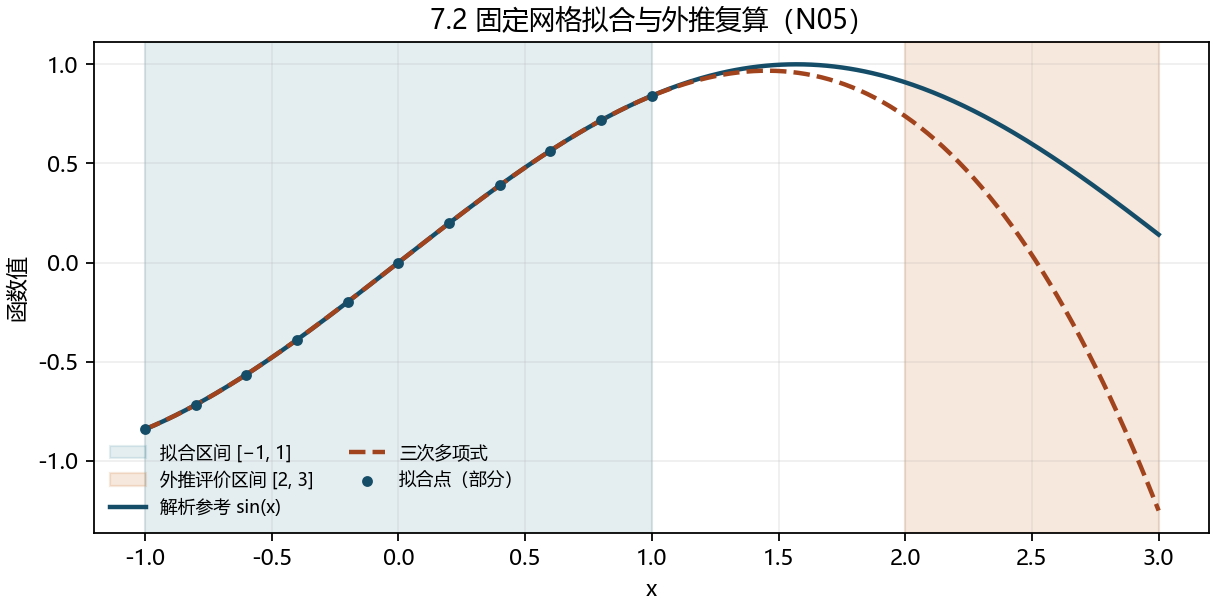

N05 实测图。基于 41 个拟合点，区间内新点和外推点的 RMSE 分别为 0.000312 和 0.727300。

In [4]:
print('N03 A1 polynomial extrapolation')
original(blocks[2],scope1,'A1 7.2原围栏')
result['N03']={'note':'原程序打印数据见该代码单元输出'}


N03 A1 polynomial extrapolation
区间                           三次均值      三次标准差       五次均值      五次标准差       基线均值
内插区 [0.5,3.5]              0.0427     0.0076     0.0305     0.0091     0.4350
邻近外推 [4.5,6.0]             1.5172     0.4684     3.4102     2.6026     1.2187
远距外推 [7.0,9.0]             3.8561     2.0457    78.9369    61.3929     0.4427


In [5]:
print('N04 A2 original dependency')
import shutil
with temporary_run() as scratch:
    try:
        original(source_a2(8),{},'A2 7.2原入口')
    except FileNotFoundError as error:
        missing = Path(error.filename).relative_to(scratch).as_posix()
        assert missing=='配套代码/experiments.py'
        print('FileNotFoundError:',missing)
        result['N04']={'missing':missing,'observed':'FileNotFoundError'}
    else:
        raise AssertionError('当前固定目录树无此依赖')


N04 A2 original dependency


FileNotFoundError: 配套代码/experiments.py


In [6]:
print('N05 A2 independent 7.2 reconstruction')
rmse=lambda a,b: float(np.sqrt(np.mean((a-b)**2)))
x=np.linspace(-1,1,41); xi=np.linspace(-.975,.975,40); xo=np.linspace(2,3,101)
grid={}
for degree in [3,5,8]:
    coef=np.polynomial.polynomial.polyfit(x,np.sin(x),degree)
    pred=lambda v: np.polynomial.polynomial.polyval(v,coef)
    grid[str(degree)]=[rmse(pred(xi),np.sin(xi)),rmse(pred(xo),np.sin(xo))]
for d, expected in {'3':[.000312,.727300],'5':[.00000194,.136527],'8':[.00000000705,.014932]}.items():
    np.testing.assert_allclose(grid[d],expected,atol=5.1e-7,rtol=0)
rg=np.random.default_rng(7201)
xt=rg.uniform(-1,1,41); x_id=rg.uniform(-1,1,1000); x_ood=rg.uniform(2,3,1000)
co=np.polynomial.polynomial.polyfit(xt,np.sin(xt),3)
sampled=[rmse(np.polynomial.polynomial.polyval(v,co),np.sin(v)) for v in [xt,x_id,x_ood]]
# 若作者实际抽样顺序有额外消费随机数，此处只算独立重建，不能冒充原代码复现。
sample_match=bool(np.allclose(sampled,[.000289,.000319,.739198],atol=5.1e-7,rtol=0))
f1=math.sin(3); f2=f1+8
assert abs((f2-f1)-8)<1e-12

grid_train = rmse(np.polynomial.polynomial.polyval(x,np.polynomial.polynomial.polyfit(x,np.sin(x),3)), np.sin(x))
assert abs(grid_train-.000341)<5.1e-7 and sample_match
rg = np.random.default_rng(7202)
parameters = [np.sort(rg.uniform(lo,hi,n)).tolist() for lo,hi,n in [(.05,.10,3),(.05,.10,2),(.05,.10,2),(.20,.50,2)]]
np.testing.assert_allclose(np.concatenate(parameters),
    [.0613,.0762,.0785,.0710,.0889,.0853,.0997,.3757,.4679],atol=5.1e-5,rtol=0)
assert len(np.unique(np.concatenate(parameters)))==9
heat = np.exp(-np.pi**2*np.array([.05,.10,.20,.50]))
result['N05']={'grid_training_rmse':grid_train,'grid':grid,'sampled':sampled,
    'heat_parameters':parameters,'heat_u_at_x05_t1':heat.tolist(),'continuations':[f1,f2]}
print(result['N05'])


N05 A2 independent 7.2 reconstruction
{'grid_training_rmse': 0.0003411223601555272, 'grid': {'3': [0.00031207021915106493, 0.7273004622080976], '5': [1.939327698060253e-06, 0.1365271872690945], '8': [7.051201911884431e-09, 0.014932200611543203]}, 'sampled': [0.00028936348649601866, 0.0003192052583225957, 0.7391980873937797], 'heat_parameters': [[0.06130116030747258, 0.07616031449820085, 0.07849341273881347], [0.07100133832399654, 0.08889294532429555], [0.08527064058495719, 0.0996518181417102], [0.3756593413829339, 0.4679173110606841]], 'heat_u_at_x05_t1': [0.6104980252657972, 0.37270783885343794, 0.13891113314280026, 0.007191883355826368], 'continuations': [0.1411200080598672, 8.141120008059866]}


### 7.3 待定节补充复核

按当前稿件补充核验。

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值 | 差异 |
| --- | --- | --- | --- | --- | --- |
| A1（N06） | 200 内点，5 个训练工况，20 个 MLP 种子 | 解族张成空间至多二维，ROM/FOM 差 <1e-10 | 秩阈值 1e-12×最大奇异值 | 秩 2。独立投影 ROM/FOM 差约 1.5e-14。原 ROM、MLP 远域均值约 5.25e-6、.2924 | 需区分离散误差、POD 截断及 MLP 拟合误差。 |
| A2（N07） | 原 PCA/POD 等 4 个实验 | POD 相对重构误差平方等于尾谱能量比例 | 原断言与恒等式 1e-12 | 原断言通过，二模态相对误差 .0001772115 | 结论限定于已跑算例。 |

In [7]:
print('N06 A1 independent rank / ROM check')
N=200; h=1/(N+1); x=np.arange(1,N+1)*h
A=(2*np.eye(N)-np.eye(N,k=1)-np.eye(N,k=-1))/h**2
eig=4*math.sin(math.pi*h/2)**2/h**2
fom=lambda mu: mu**2/eig*np.sin(math.pi*x)+mu*x*(1-x)
exact=lambda mu: mu**2/math.pi**2*np.sin(math.pi*x)+mu*x*(1-x)
S=np.column_stack([fom(mu) for mu in [.1,.2,.3,.4,.5]])
U,s,Vt=np.linalg.svd(S,full_matrices=False); basis=U[:,:2]
rank=int(np.sum(s>s[0]*1e-12)); assert rank==2
vals=[]
for mu in [.15,.45,.6,.75,1.0]:
    rhs=mu**2*np.sin(math.pi*x)+2*mu
    rom=basis@np.linalg.solve(basis.T@A@basis,basis.T@rhs)
    ef=float(np.linalg.norm(rom-fom(mu))/np.linalg.norm(fom(mu)))
    ee=float(np.linalg.norm(rom-exact(mu))/np.linalg.norm(exact(mu)))
    assert ef<1e-10
    vals.append({'mu':mu,'relative_to_FOM':ef,'relative_to_exact':ee})
result['T05']={'rank':rank,'singular_values':s.tolist(),'errors':vals}
print(json.dumps(result['T05'],ensure_ascii=False,indent=2))
try:
    import torch
except ModuleNotFoundError:
    result['N06']={'MLP':'未运行：环境缺 PyTorch'}
    print(result['N06'])
else:
    torch.set_num_threads(1)
    print('Torch CPU:',torch.__version__)
    original(blocks[3],scope1,'A1 7.3原围栏')
    groups=scope1['groups']
    result['N06']={'torch':torch.__version__,'MLP':'原围栏完成',
        'relative_errors':{kind:{g: float(np.mean(scope1[kind][g])) for g in groups}
            for kind in ('rom_errs','mlp_errs')},
        'rank':int(np.sum(scope1['S']>scope1['S'][0]*1e-12))}
    assert result['N06']['rank']==2
    print(result['N06'])


N06 A1 independent rank / ROM check
{
  "rank": 2,
  "singular_values": [
    2.2289695100741773,
    0.0025443982230625565,
    2.7725405986377134e-16,
    6.70586658406161e-17,
    5.4146295129633036e-17
  ],
  "errors": [
    {
      "mu": 0.15,
      "relative_to_FOM": 1.50912489107227e-14,
      "relative_to_exact": 1.131737810028213e-06
    },
    {
      "mu": 0.45,
      "relative_to_FOM": 1.5014941971715342e-14,
      "relative_to_exact": 3.0556677601384265e-06
    },
    {
      "mu": 0.6,
      "relative_to_FOM": 1.4836710841605466e-14,
      "relative_to_exact": 3.880184450721246e-06
    },
    {
      "mu": 0.75,
      "relative_to_FOM": 1.426942270388879e-14,
      "relative_to_exact": 4.629725015288542e-06
    },
    {
      "mu": 1.0,
      "relative_to_FOM": 1.4729422067239667e-14,
      "relative_to_exact": 5.738155842041545e-06
    }
  ]
}


Torch CPU: 2.9.1+cpu


区间             ROM 均值     ROM 标准差     MLP 均值     MLP 标准差
分布内          2.12e-06    7.17e-07   9.61e-02    8.14e-02
边界邻近         3.88e-06    2.14e-07   1.39e-01    5.05e-02
远距外推         5.25e-06    4.26e-07   2.92e-01    6.91e-02
{'torch': '2.9.1+cpu', 'MLP': '原围栏完成', 'relative_errors': {'rom_errs': {'分布内': 2.1162150506207535e-06, '边界邻近': 3.877413160414931e-06, '远距外推': 5.2474219923639126e-06}, 'mlp_errs': {'分布内': 0.09609017479095446, '边界邻近': 0.1389982678024003, '远距外推': 0.2924052286842391}}, 'rank': 2}


In [8]:
print('N07 A2 original 7.3 cells')
s = {}
with temporary_run() as scratch:
    for index in [27,29,31,33,35,37]:
        original(source_a2(index),s,f'A2 7.3 单元 {index+1}')
    np.testing.assert_allclose(s['snap_err'][2]**2, np.sum(s['s2'][2:]**2)/np.sum(s['s2']**2),atol=1e-12,rtol=0)
    result['N07']={'original_assertions':'通过','POD_error_rank2':s['snap_err'][2],
        'results':s['results'],'generated_images':sorted(p.name for p in (scratch/'图片').glob('*.png'))}


N07 A2 original 7.3 cells
工作目录: C:\Users\13439\AppData\Local\Temp\ch07-b2-mj8c3n33
numpy 2.3.5


奇异值          = [26.9608 10.0957  6.0084]
能量占比        = [0.8404 0.1178 0.0417]
累计能量        = [0.8404 0.9583 1.    ]
重构误差 k=1,2,3 = [0.399479, 0.204304, 0.0]
已保存图：fig7-3-实验一-弹珠主轴.png / fig7-3-实验一-能量谱.png


奇异值(前6)     = [4.2603942e+01 1.7028944e+01 1.7340000e-03 1.7060000e-03 1.6670000e-03
 1.6190000e-03]
累计能量(前6)   = [0.862245 1.       1.       1.       1.       1.      ]
重构误差 k=1,2,3 = [0.371153, 0.000177, 0.000173]
已保存图：fig7-3-实验二-POD模态.png


次数  训练MSE      测试MSE
   1   0.257653   0.222036
   2   0.204768   0.254107
   3   0.014769   0.014003
   4   0.014291   0.015059
   5   0.007422   0.010822
   6   0.007396   0.010767
   7   0.007355   0.011391
   8   0.006822   0.013550
   9   0.006332   1.211789
  10   0.000367   73.677603
  11   0.000000   6931.415374
  12   0.000000   3048.946167
  13   0.000000   16486.395707
  14   0.000000   8602.197010
  15   0.000000   34082.323158
测试误差最小的次数 = 6
已保存图：fig7-3-实验三-过拟合.png


瓶颈宽 k   PCA误差      AE误差
  1        0.864313   0.864327
  2        0.709347   0.709348
  3        0.587932   0.587932
  5        0.370030   0.370034
  8        0.109689   0.109733
已保存图：fig7-3-实验四-自编码器vsPCA.png
结果已写入: C:\Users\13439\AppData\Local\Temp\ch07-b2-mj8c3n33\数据\7.3-实验结果.json
图片已写入: ['fig7-3-实验一-弹珠主轴.png', 'fig7-3-实验一-能量谱.png', 'fig7-3-实验三-过拟合.png', 'fig7-3-实验二-POD模态.png', 'fig7-3-实验四-自编码器vsPCA.png']
全部断言通过。


## 7.4 AI关联：不确定性量化（2学时）

| 被审版本 | 测试输入 | 参考值 | 容差 | 实测值 | 差异 |
| --- | --- | --- | --- | --- | --- |
| A1（N08） | 训练 100，校准量 50/200/1000，标称 80%/90%/95% 各重复 100 次，两固定测试集各 2000 | 同一 q 的区间同宽，有限测试比例随样本和校准变化 | 宽度 1e-12，覆盖率报告描述统计 | 校准 50、标称 90%，域内/域外 .89444/.07888，均宽 .338031 | 域内较标称低 .556 个百分点。100 次域内覆盖率标准差 .05175。 |
| A2（N09） | 种子 2026，校准、域内测试及域外测试各 1000，标称 80% | 同配置历史值，两个域的分数同分布 | 固定输出 1e-12 | 域内 81.3%、域外 80.1%，均宽 .821345574 | 较标称高 1.3 和 0.1 个百分点。原文字仍写“大幅塌陷”。 |
| A2（N09–N10） | n=1、标称 90% 的分位边界。另给原域外目标加 1.5 | 边界 q 应取 +∞。条件偏移时覆盖可变，固定 q 同宽 | 精确边界对照，宽度 1e-12 | 原函数 q=.2。加偏移时域外覆盖实测 0%，宽度保持 .821345574 | 小样本裁剪需修。偏移对照为 B 独立构造。 |

In [9]:
print('N08 A1 conformal')
original(blocks[4],scope1,'A1 7.4原围栏')
result['N08']={f'{n}:{alpha}':v for (n,alpha),v in scope1['results'].items()}
width_deltas=[abs(v['wid_in'][0]-v['wid_out'][0]) for v in scope1['results'].values()]
assert max(width_deltas)<1e-12
print('n=50 and target=.90',result['N08']['50:0.1'])


N08 A1 conformal


 n_cal  1-alpha   cov_in  cov_out  width_in  width_out
    50     0.80    0.803    0.065     0.266      0.266
    50     0.90    0.894    0.079     0.338      0.338
    50     0.95    0.964    0.076     0.436      0.436
   200     0.80    0.802    0.044     0.264      0.264
   200     0.90    0.898    0.069     0.336      0.336
   200     0.95    0.955    0.112     0.404      0.404
  1000     0.80    0.798    0.034     0.261      0.261
  1000     0.90    0.899    0.086     0.336      0.336
  1000     0.95    0.954    0.082     0.400      0.400
n=50 and target=.90 {'cov_in': (np.float64(0.89444), np.float64(0.05174887824871183)), 'cov_out': (np.float64(0.07887999999999999), np.float64(0.16734950134374466)), 'wid_in': (np.float64(0.33803106985234826), np.float64(0.04786523387030838)), 'wid_out': (np.float64(0.33803106985234826), np.float64(0.04786523387030838))}


In [10]:
print('N09 A2 7.4 original')
s = {}
raw = original(source_a2(39),s,'A2 7.4原单元')
np.testing.assert_allclose([s['q'],s['picp_in'],s['picp_out'],s['mpiw_in'],s['mpiw_out']],
    [.410672786967,.813,.801,.821345573934,.821345573934],atol=1e-12,rtol=0)
q1 = s['compute_q'](np.array([0.]),np.array([0.3]),alpha=.1)
assert np.isfinite(q1) and math.ceil(2*.9)==2
result['N09']={'q':s['q'],'in':s['picp_in'],'out':s['picp_out'],
    'width':s['mpiw_out'],'n1_alpha01_q_actual':float(q1),'n1_alpha01_reference':'+infinity'}
print(result['N09'])
print('N10 independent positive control')
# 在已生成的域外目标值加入 +1.5。校准、预测器和输入均固定，只改变 Y|X。
shifted, width = s['evaluate_coverage'](s['x_test_out'],s['y_test_out']+1.5,s['q'])
assert shifted<.01 and abs(width-s['mpiw_out'])<1e-12
# n=9 连续均匀分数下，固定校准集条件覆盖 q 的分布为 Beta(8,2)。
beta_cdf_at_target = 9*.8**8-8*.8**9
assert abs(beta_cdf_at_target-.436207616)<1e-12
binary_contains=[.67<=y<=.97 for y in (0,1)]
assert not any(binary_contains)
result['N10']={'shifted_ood_PICP':shifted,'width':width,
    'prob_fixed_cal_coverage_under_0.8':beta_cdf_at_target,'binary_contains':binary_contains}
print(result['N10'])


N09 A2 7.4 original
设定的阈值 q = 0.4107
域内测试: PICP = 0.8130, MPIW = 0.8213
域外测试: PICP = 0.8010, MPIW = 0.8213
结论：MPIW 没变（因为 q 没变），但域外 PICP 大幅塌陷，分布偏移破坏了可交换性假设。
{'q': np.float64(0.41067278696708664), 'in': np.float64(0.813), 'out': np.float64(0.801), 'width': np.float64(0.8213455739341734), 'n1_alpha01_q_actual': 0.19999999999999998, 'n1_alpha01_reference': '+infinity'}
N10 independent positive control
{'shifted_ood_PICP': np.float64(0.0), 'width': np.float64(0.8213455739341734), 'prob_fixed_cal_coverage_under_0.8': 0.43620761600000035, 'binary_contains': [False, False]}


## 复现结论与修正清单

A1 四节围栏程序提取后完成运行，原 Notebook 仍需补可执行单元。A2 的 7.2 入口需补脚本，7.4 需修正结论及小样本分位边界。11 个单元保留原执行输出。

[验证报告](B2组-验证报告.md) · [修正清单](B2组-修正清单.md)

In [11]:
print('复测结果汇总（包含环境及 N01–N10）')
print(json.dumps(result, ensure_ascii=False, indent=2, default=float))

复测结果汇总（包含环境及 N01–N10）
{
  "environment": {
    "system": "Windows-11-10.0.22631-SP0",
    "python": "3.12.14",
    "device": "CPU",
    "packages": {
      "numpy": "2.3.5",
      "matplotlib": "3.10.7",
      "pandas": "3.0.1",
      "reportlab": "4.4.9",
      "pypdfium2": "5.13.0",
      "nbformat": "5.10.4",
      "nbclient": "0.10.2",
      "ipykernel": "6.29.5"
    }
  },
  "commit": "7ee42a1594f5dc4036a44f71cc876194dde9b8ae",
  "A1_executable_cells": 0,
  "A1_closed_python_fences": 5,
  "N01": {
    "records": [
      {
        "n": 10,
        "emp_mean": 0.0875,
        "true_mean": 0.1780995,
        "true_std": 0.10027904500068795,
        "bound_mean": 0.6068085569462708,
        "violation_rate": 0.0
      },
      {
        "n": 20,
        "emp_mean": 0.09025000000000002,
        "true_mean": 0.13089765000000003,
        "true_std": 0.05268802529965893,
        "bound_mean": 0.4574566021449084,
        "violation_rate": 0.0
      },
      {
        "n": 50,
        "emp_